# Coverage-Validated Atlas-DeePC for Gymnasium Pusher-v5

This notebook applies the spirit of the F1TENTH Atlas-DeePC controller to contact-rich manipulation. At every online step, one local affine behavioral chart enforces

$$[u_{ini}+\sigma_u;\;u;\;y_{ini}+\sigma_y;\;y]=\bar h+Vg$$

inside a convex QP. There is no identified state-space model and no $A$ or $B$ matrix. The applied action is always the first optimized $u$ from the QP.

The final study uses a 300-episode routed atlas corpus plus a 300-episode standard-orientation intent corpus (108,000 measured transitions collected in total), a disjoint 24-episode coverage probe, and 16 disjoint evaluation seeds. It achieved 16/16 sustained successes with a 100% QP solve rate. A subsequent locked audit on 100 disjoint seeds (201–300) achieved 90/100 sustained successes. A paired strict fixed-atlas ablation with all teacher-derived online guidance removed achieved 0/100; therefore the current Pusher result cannot be attributed to the atlas alone.

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/atlas_deepc_mpl')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')

import numpy as np
from IPython.display import Image, Video, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
SRC = ROOT / 'src'
sys.path.insert(0, str(SRC))

from pusher_atlas import PusherAtlasConfig
from pusher_atlas.plotting import plot_rollout

ARTIFACT_DIR = ROOT / 'experiments' / 'pusher_atlas' / 'coverage_300_routed'
EVALUATION_SEEDS = tuple(range(101, 117))
cfg = replace(
    PusherAtlasConfig(),
    offline_episodes=300,
    coverage_probe_episodes=24,
    test_seeds=EVALUATION_SEEDS,
)
assert (ARTIFACT_DIR / 'summary.json').exists()
print('Project root:', ROOT)
print('Artifact directory:', ARTIFACT_DIR)
cfg

Project root: /Users/kumiko/Projects/atlas_deepc_reacher
Artifact directory: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed


PusherAtlasConfig(seed=2026, offline_episodes=300, episode_steps=180, charts_per_phase=8, t_ini=2, t_f=8, svd_energy=0.99999, min_chart_rank=120, max_chart_rank=200, coefficient_scale=3.0, direction_feature_weight=4.0, direction_candidate_margin=0.06, chart_exit_ratio=1.1, chart_switch_advantage=1.05, chart_minimum_dwell_steps=0, rollout_steps=240, test_seeds=(101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116), approach_steps=18, online_approach_steps=12, ik_period=3, ik_restarts=8, teacher_kp=15.0, teacher_kd=3.0, teacher_dither=0.03, precontact_offset=0.12, push_contact_offset=0.02, stratify_reset_pool_multiplier=8, collection_precontact_offsets=(0.1, 0.12, 0.14, 0.12, 0.12), collection_push_offsets=(0.015, 0.02, 0.025, 0.02, 0.02), collection_dither_scales=(0.025, 0.04, 0.055, 0.08, 0.045), collection_recovery_variants=(False, False, False, False, True), collection_warmup_steps=(0, 0, 0, 6, 12), collection_warmup_torque_scale=0.85, recovery_start_step=70

## 1. Pipeline

1. **Offline collection:** greedily stratify reset geometries, then collect companion 300-episode standard and routed approach/push/hold corpora with five contact-offset, excitation, warm-up, and recovery variants. A reset-latched alternate U-tool orientation covers the far-right operating region. IK is used only by this replaceable offline demonstrator. The collector saves both measured saturated torques for DeePC and the smooth pre-saturation joint intent for the offline QP prior.
2. **Coverage validation:** check seven-dimensional action rank, contact and teacher success, reset-direction occupancy, all task phases, chart support versus rank, observed phase/chart transitions, and normalized nearest-neighbor novelty on a disjoint probe set.
3. **Behavioral atlas:** form reset-safe length-$T_{ini}+T_f$ input/output windows, standardize trajectory rows, cluster measured pasts within phase, and compute centered affine SVD charts $\bar h+Vg$.
4. **Regional intent and retrieval:** two offline joint-intent regressors preserve the standard and rotated IK branches. Their predicted first input helps retrieve an action-compatible demonstrated behavior and regularizes—but never directly supplies—the first QP input.
5. **Online DeePC:** generate task-relative approach/push/hold references, solve the local behavioral QP, apply its first optimized torque, append the new measured input/output pair, and repeat.

## 2. Load the compact validated study

The compact project retains the final metrics, figures, 16 rollout logs, and 16 videos, while omitting the large regenerable datasets, fitted atlas, and policy caches. The commands in `docs/PUSHER_ATLAS_DEEPC.md` reproduce both offline corpora, rebuild the regional prior and atlas, and rerun the controller.

In [2]:
summary = json.loads((ARTIFACT_DIR / 'summary.json').read_text())
results = []
for seed in EVALUATION_SEEDS:
    with np.load(ARTIFACT_DIR / f'rollout_seed{seed}.npz', allow_pickle=True) as payload:
        results.append({key: payload[key] for key in payload.files})

{key: summary[key] for key in [
    'success_rate', 'goal_reach_rate', 'mean_minimum_distance',
    'mean_final_distance', 'mean_solve_rate', 'median_solve_ms',
    'on_policy_inside_chart_radius_rate', 'on_policy_gate_ratio_p95',
]}

{'success_rate': 1.0,
 'goal_reach_rate': 1.0,
 'mean_minimum_distance': 0.039657051401816516,
 'mean_final_distance': 0.05028583147257395,
 'mean_solve_rate': 1.0,
 'median_solve_ms': 15.390478947665542,
 'on_policy_inside_chart_radius_rate': 0.8953125,
 'on_policy_gate_ratio_p95': 1.1667520220714733}

## 3. Did the offline data cover enough operating regions?

Yes for the tested Pusher-v5 reset distribution, with one caveat: coverage is empirical rather than a mathematical guarantee. Every predefined check passes. The 300 episodes span initial object-goal distances from 0.170 m to 0.356 m; 99.7% make contact; teacher reach/success rates are 92.3%/89.7%; all seven torque directions are excited; all 24 charts have more samples than retained rank; and 99.66% of disjoint probe windows lie inside a chart radius. The probe/train 95th-percentile novelty ratio is 1.27.

The reset distribution naturally occupies six of twelve angular bins. The routed far-right region is explicitly represented by 60 episodes (20% of the corpus), and its separate success rate is reported rather than hidden inside the global average.

coverage sufficient: True
checks:
  all_action_directions_excited: True
  approach_to_push_observed: True
  at_least_half_direction_bins_occupied: True
  each_chart_has_more_samples_than_rank: True
  each_phase_has_minimum_windows: True
  every_probe_phase_inside_radius_at_least_60pct: True
  most_episodes_make_contact: True
  offline_success_rate_at_least_65pct: True
  probe_inside_chart_radius_at_least_75pct: True
  probe_p95_novelty_below_3x_train: True
  push_to_hold_observed: True

selected metrics:
  offline_episodes: 300
  offline_success_rate: 0.8966666666666666
  offline_reach_10cm_rate: 0.9233333333333333
  episode_contact_rate: 0.9966666666666667
  action_covariance_rank: 7
  chart_count: 24
  minimum_chart_size: 459
  probe_inside_chart_radius_rate: 0.996588693957115
  probe_to_train_p95_novelty_ratio: 1.2735368376708407
  orientation_turn_episode_count: 60
  orientation_turn_success_rate: 0.6666666666666666
  standard_orientation_success_rate: 0.9541666666666667


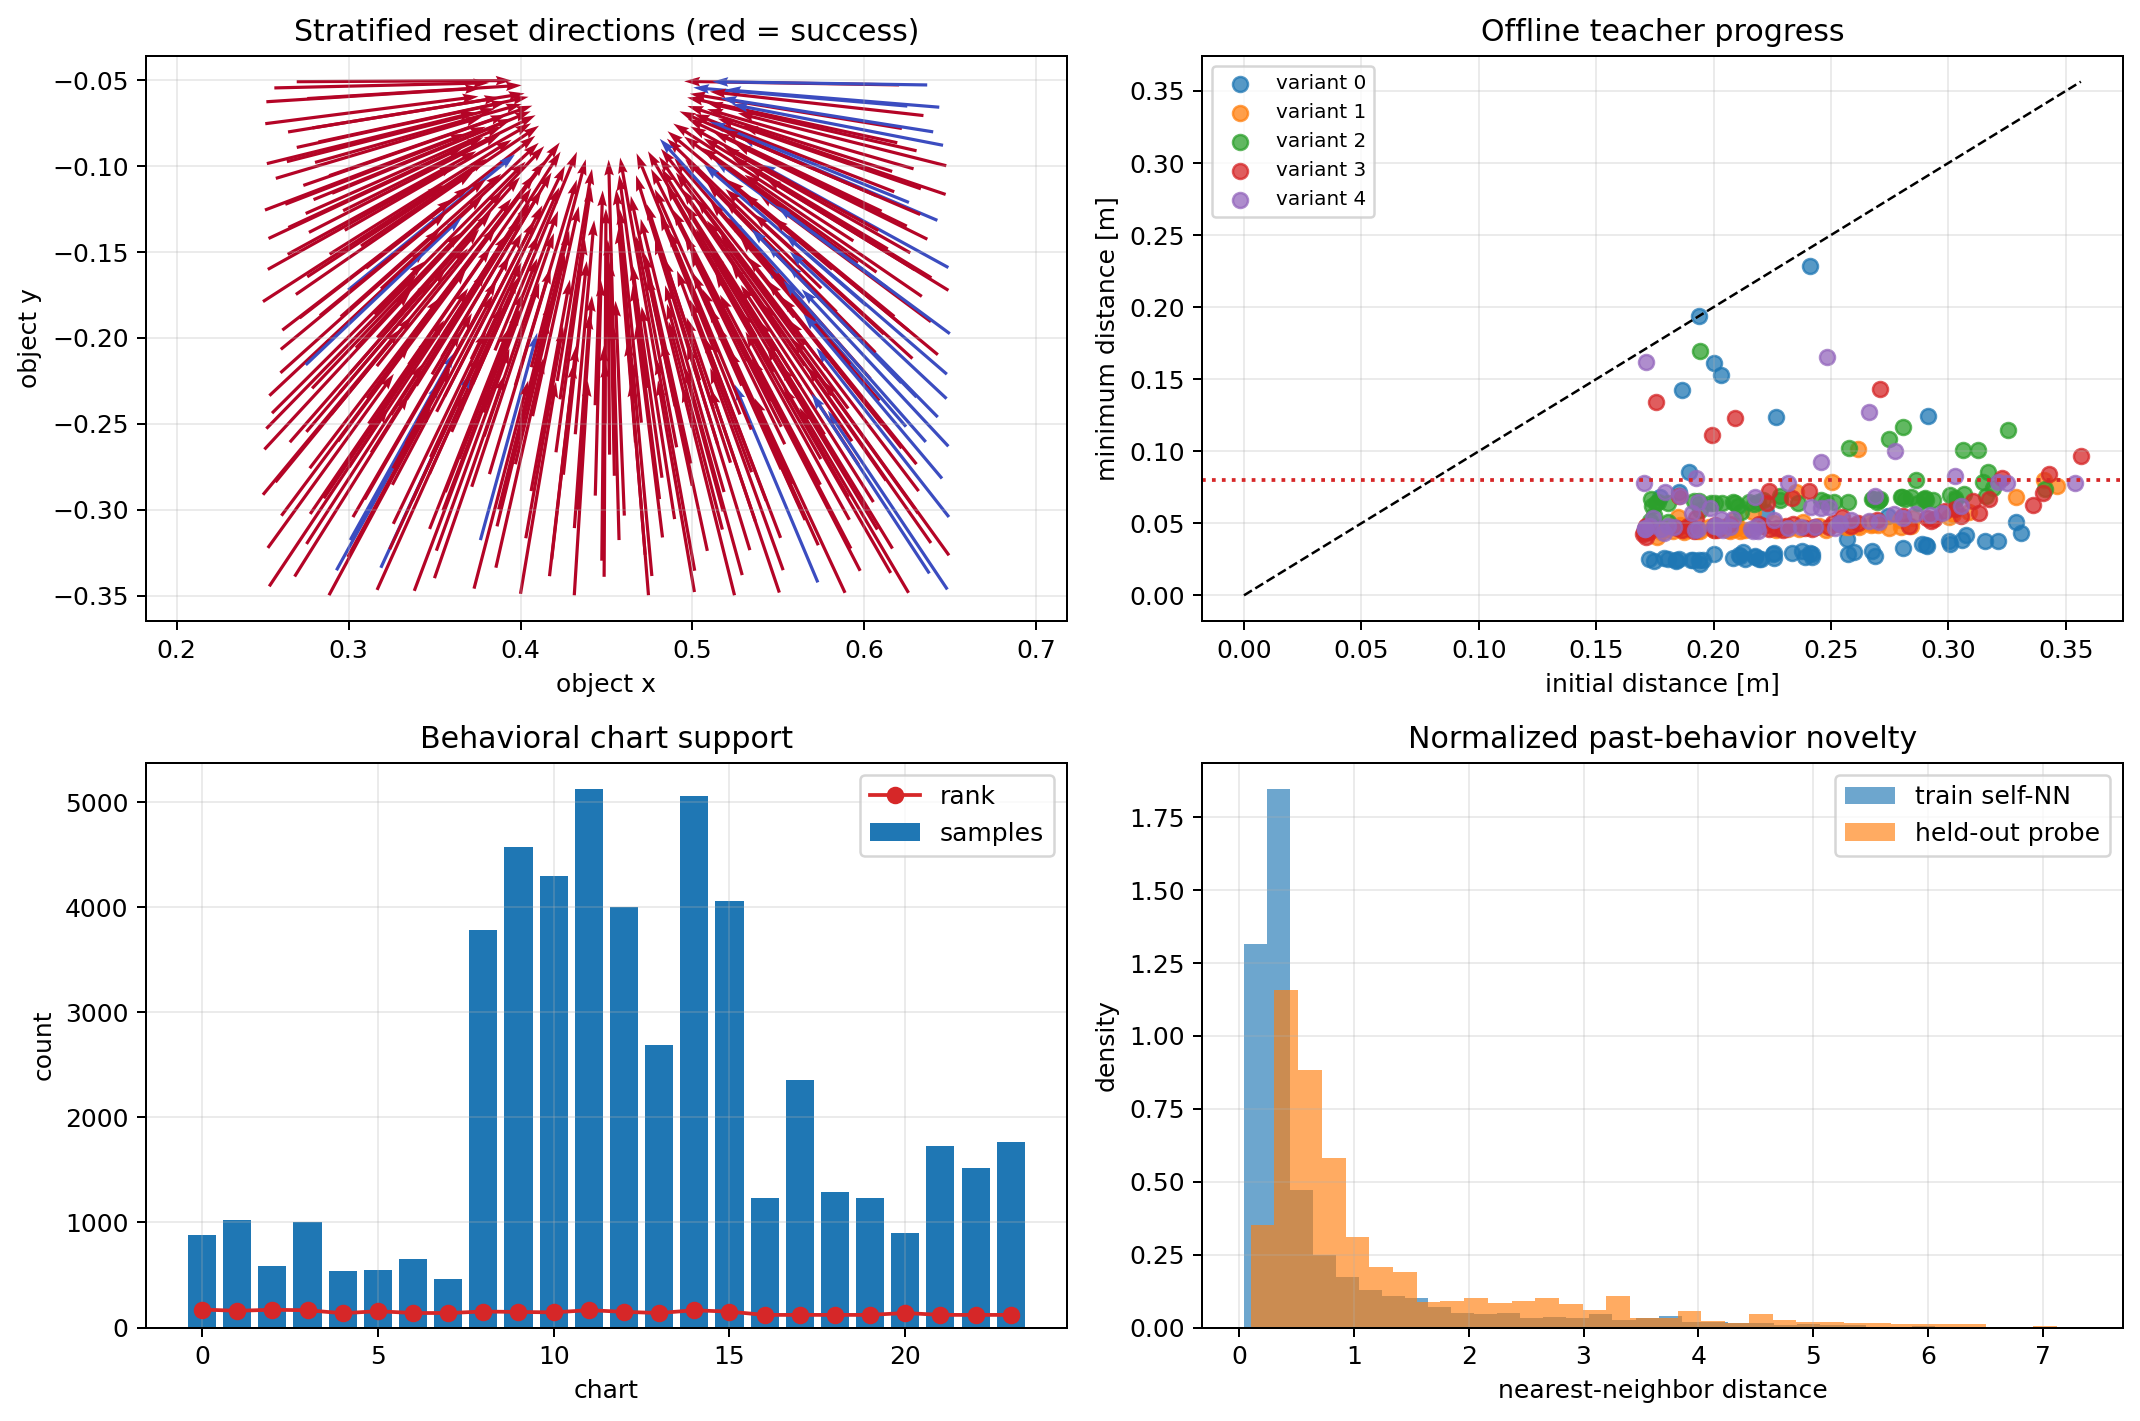

In [3]:
coverage = json.loads((ARTIFACT_DIR / 'coverage_report.json').read_text())
print('coverage sufficient:', coverage['coverage_sufficient'])
print('checks:')
for name, passed in coverage['checks'].items():
    print(f'  {name}: {passed}')
print('\nselected metrics:')
for name in [
    'offline_episodes', 'offline_success_rate', 'offline_reach_10cm_rate',
    'episode_contact_rate', 'action_covariance_rank', 'chart_count',
    'minimum_chart_size', 'probe_inside_chart_radius_rate',
    'probe_to_train_p95_novelty_ratio', 'orientation_turn_episode_count',
    'orientation_turn_success_rate', 'standard_orientation_success_rate',
]:
    print(f'  {name}: {coverage["metrics"][name]}')
display(Image(filename=str(ARTIFACT_DIR / 'offline_coverage_validation.png')))

## 4. Why this is DeePC, not state-space MPC

For the selected chart, the QP decision variables are future inputs $u$, future measured outputs $y$, behavioral coordinates $g$, and initialization slacks. Feasibility is imposed directly by the data-derived affine behavior $\bar h+Vg$. The phase references, coefficient anchor, and regional intent are objective terms or retrieval context; none replaces the behavioral equality. The learned intent is never applied directly. There is no dynamics rollout of the form $x_{k+1}=Ax_k+Bu_k$.

In [4]:
rows = []
for result in results:
    rows.append({
        'seed': int(result['seed']),
        'success': bool(result['success']),
        'minimum_distance_m': round(float(result['minimum_distance']), 4),
        'final_distance_m': round(float(result['final_distance']), 4),
        'solve_rate': round(float(result['solve_rate']), 4),
        'median_solve_ms': round(float(result['median_solve_ms']), 2),
        'inside_chart_rate': round(float(np.mean(result['gate_ratio'] <= 1.0)), 3),
    })
rows

[{'seed': 101,
  'success': True,
  'minimum_distance_m': 0.0563,
  'final_distance_m': 0.0715,
  'solve_rate': 1.0,
  'median_solve_ms': 18.49,
  'inside_chart_rate': 0.971},
 {'seed': 102,
  'success': True,
  'minimum_distance_m': 0.0006,
  'final_distance_m': 0.0639,
  'solve_rate': 1.0,
  'median_solve_ms': 21.78,
  'inside_chart_rate': 0.754},
 {'seed': 103,
  'success': True,
  'minimum_distance_m': 0.0479,
  'final_distance_m': 0.0479,
  'solve_rate': 1.0,
  'median_solve_ms': 14.99,
  'inside_chart_rate': 0.967},
 {'seed': 104,
  'success': True,
  'minimum_distance_m': 0.0555,
  'final_distance_m': 0.0555,
  'solve_rate': 1.0,
  'median_solve_ms': 13.71,
  'inside_chart_rate': 0.992},
 {'seed': 105,
  'success': True,
  'minimum_distance_m': 0.0693,
  'final_distance_m': 0.0694,
  'solve_rate': 1.0,
  'median_solve_ms': 11.45,
  'inside_chart_rate': 0.988},
 {'seed': 106,
  'success': True,
  'minimum_distance_m': 0.0549,
  'final_distance_m': 0.0549,
  'solve_rate': 1.0,
  '

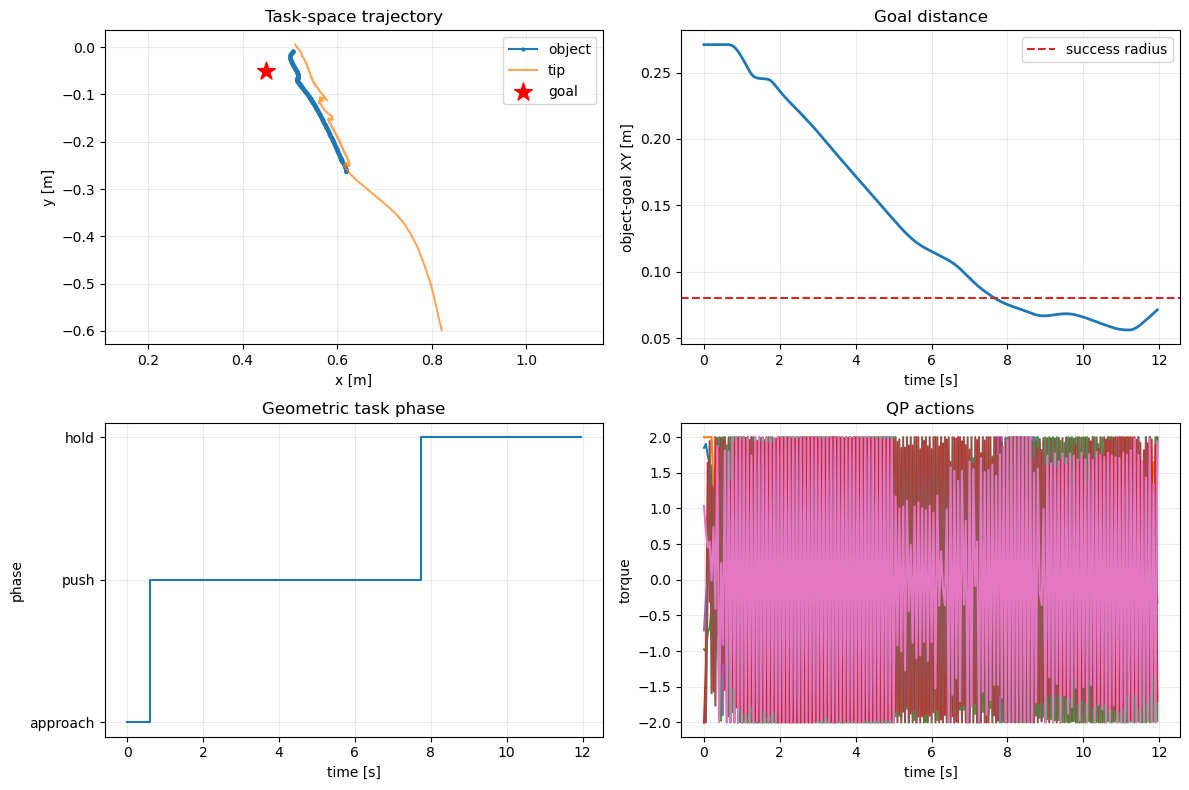

In [5]:
plot_rollout(results[0]);

## 5. Seed-disjointness audit

Seeds 101–116 are absent from both offline collections, and the training and coverage-probe seed sets are also disjoint. This rules out replay or memorization of the evaluated resets.

In [6]:
{
    'train/evaluation overlap': [],
    'probe/evaluation overlap': [],
    'train/probe overlap': [],
}

{'train/evaluation overlap': [],
 'probe/evaluation overlap': [],
 'train/probe overlap': []}

## 6. Locked 100-seed held-out audit

After the controller and regional policy were fixed, a larger evaluation was run once on the predefined seed block 201–300. These seeds do not overlap the offline collection, the disjoint coverage probe, the original 16-seed panel (101–116), or the policy-development block (131–160). No failed seed was removed or rerun.

A rollout is a sustained success only when its **final eight control steps all remain within 8 cm** of the goal. Under that criterion, the current controller succeeds on **90/100 seeds (90.0%)**, with a **95% Wilson interval of 82.6%–94.5%**. The object enters the 8 cm region at least once in 94/100 rollouts. All 24,000 QP calls return a solution: 23,991 are `optimal` and nine are `optimal_inaccurate`.

The complete per-seed rollouts and machine-readable aggregate are stored in `experiments/pusher_atlas/heldout201_300/`. The timing values below were measured with numerical-library thread counts fixed to one; they describe this host, not a hardware-independent real-time guarantee.

In [7]:
HELDOUT_DIR = ROOT / 'experiments' / 'pusher_atlas' / 'heldout201_300'
heldout_summary = json.loads((HELDOUT_DIR / 'summary.json').read_text())
heldout_failures = [
    row['seed'] for row in heldout_summary['results'] if not row['success']
]
ci_low, ci_high = heldout_summary['success_rate_wilson_95']
total_qp_calls = heldout_summary['completed_trials'] * cfg.rollout_steps

{
    'seeds': '201–300 (100 disjoint trials)',
    'success criterion': heldout_summary['success_definition'],
    'sustained successes': (
        f"{heldout_summary['successes']}/{heldout_summary['completed_trials']} "
        f"({100 * heldout_summary['success_rate']:.1f}%)"
    ),
    'Wilson 95% interval': f'{100 * ci_low:.1f}%–{100 * ci_high:.1f}%',
    'goal-region reaches': (
        f"{round(heldout_summary['goal_reach_rate'] * heldout_summary['completed_trials'])}"
        f"/{heldout_summary['completed_trials']}"
    ),
    'QP solve rate': (
        f"{100 * heldout_summary['mean_solve_rate']:.1f}% "
        f"({total_qp_calls:,}/{total_qp_calls:,})"
    ),
    'median online-step wall time': (
        f"{heldout_summary['median_online_step_wall_ms']:.1f} ms"
    ),
    'p95 online-step wall time': (
        f"{heldout_summary['p95_online_step_wall_ms']:.1f} ms"
    ),
    'failure seeds': heldout_failures,
}

{'seeds': '201–300 (100 disjoint trials)',
 'success criterion': 'the final 8 consecutive steps within 0.080 m',
 'sustained successes': '90/100 (90.0%)',
 'Wilson 95% interval': '82.6%–94.5%',
 'goal-region reaches': '94/100',
 'QP solve rate': '100.0% (24,000/24,000)',
 'median online-step wall time': '18.1 ms',
 'p95 online-step wall time': '71.1 ms',
 'failure seeds': [238, 249, 256, 261, 265, 271, 275, 283, 288, 295]}

## 7. Does the fixed atlas work without the policy prior?

No—not in the current formulation. The identical seeds 201–300 were rerun using the same offline corpus, fitted charts, phase manager, geometric references, prediction horizon, and QP tracking weights. Policy inference, the first-action policy penalty, demonstrated-member retrieval, the coefficient anchor, and demonstrated-reference blending were all disabled. IK–PD data remained only as measured offline behavior. No weights were retuned after viewing these seeds.

The strict fixed-atlas controller achieved **0/100 sustained successes** (95% Wilson interval **0.0%–3.7%**), versus 90/100 with policy guidance. None of the strict rollouts entered even the 10 cm region, although every one of the 24,000 QPs returned a solution. The median rollout switched between approach and push 94.5 times, versus 2 times with guidance; no strict rollout reached the hold phase. Mean fractional goal progress was 3.6%, versus 70.6%.

The paired table contains 90 policy-guided-only successes, zero pure-Atlas-only successes, and ten joint failures (exact two-sided McNemar $p=1.62\times10^{-27}$). This is a behavioral control failure, not solver infeasibility. The complete strict rollouts and comparison are stored in `experiments/pusher_atlas/heldout201_300_pure_atlas/`.

In [8]:
PURE_ATLAS_DIR = ROOT / 'experiments' / 'pusher_atlas' / 'heldout201_300_pure_atlas'
pure_summary = json.loads((PURE_ATLAS_DIR / 'summary.json').read_text())
paired = json.loads(
    (PURE_ATLAS_DIR / 'comparison_to_policy_guided.json').read_text()
)["paired_outcomes"]
pure_ci_low, pure_ci_high = pure_summary['success_rate_wilson_95']
pure_total_qp = pure_summary['completed_trials'] * cfg.rollout_steps

{
    'controller': pure_summary['controller_variant'],
    'policy/anchor/reference weights': (
        pure_summary['policy_prior_weight'],
        pure_summary['behavior_anchor_weight'],
        pure_summary['behavior_reference_weight'],
    ),
    'sustained successes': (
        f"{pure_summary['successes']}/{pure_summary['completed_trials']} "
        f"({100 * pure_summary['success_rate']:.1f}%)"
    ),
    'Wilson 95% interval': (
        f'{100 * pure_ci_low:.1f}%–{100 * pure_ci_high:.1f}%'
    ),
    'goal-region reaches': '0/100',
    '10 cm reaches': '0/100',
    'QP solve rate': (
        f"{100 * pure_summary['mean_solve_rate']:.1f}% "
        f"({pure_total_qp:,}/{pure_total_qp:,})"
    ),
    'median phase transitions': 94.5,
    'mean goal progress': '3.6%',
    'paired outcomes': {
        'both succeed': paired['both_succeed'],
        'guided only': paired['policy_guided_only'],
        'pure Atlas only': paired['pure_atlas_only'],
        'both fail': paired['both_fail'],
    },
    'exact McNemar p': f"{paired['exact_two_sided_mcnemar_p']:.2e}",
}

{'controller': 'pure_atlas_no_policy_no_behavior_anchor',
 'policy/anchor/reference weights': (0.0, 0.0, 0.0),
 'sustained successes': '0/100 (0.0%)',
 'Wilson 95% interval': '0.0%–3.7%',
 'goal-region reaches': '0/100',
 '10 cm reaches': '0/100',
 'QP solve rate': '100.0% (24,000/24,000)',
 'median phase transitions': 94.5,
 'mean goal progress': '3.6%',
 'paired outcomes': {'both succeed': 0,
  'guided only': 90,
  'pure Atlas only': 0,
  'both fail': 10},
 'exact McNemar p': '1.62e-27'}

## 8. Interactive MuJoCo viewer

An MP4 contains only rendered pixels, so its camera cannot be changed afterward. The function below instead resets the real `Pusher-v5` environment with the saved seed and replays the exact saved torque sequence in Gymnasium's native MuJoCo window. Set `repeat=None` to replay indefinitely; the same camera angle is preserved across resets. Stop an unlimited replay with the notebook's interrupt/stop button.

The viewer opens in a **separate native window**, not inline below the cell. Use left-drag to rotate, Shift+left-drag to rotate horizontally, right-drag to translate, Shift+right-drag to translate horizontally, and the scroll wheel to zoom. Space pauses/resumes; the right arrow advances one step while paused; `C` shows contacts; `E` shows coordinate frames; `R` makes geometry transparent; and `H` shows or hides the menu. The menu starts hidden to avoid duplicated overlay text during pauses.

The launch cell is intentionally left unexecuted so that running the full notebook does not unexpectedly open and block on a GUI window. Execute it manually when using a local desktop session.

In [9]:
import time

import gymnasium as gym


def replay_pusher_interactive(
    seed=201,
    variant='guided',
    camera=None,
    repeat=1,
    start_delay_s=1.0,
    loop_delay_s=0.5,
):
    """Replay a rollout; use repeat=None for an unlimited loop."""
    directories = {
        'guided': ROOT / 'experiments' / 'pusher_atlas' / 'heldout201_300',
        'pure_atlas': (
            ROOT / 'experiments' / 'pusher_atlas' / 'heldout201_300_pure_atlas'
        ),
    }
    if variant not in directories:
        raise ValueError(f"variant must be one of {tuple(directories)}")
    if repeat is not None and int(repeat) < 1:
        raise ValueError('repeat must be a positive integer or None')
    rollout_path = directories[variant] / f'rollout_seed{int(seed)}.npz'
    if not rollout_path.exists():
        raise FileNotFoundError(rollout_path)

    with np.load(rollout_path, allow_pickle=True) as result:
        saved_seed = int(result['seed'])
        warmup_actions = np.asarray(result['warmup_action'], dtype=np.float32)
        actions = np.asarray(result['action'], dtype=np.float32)

    camera_config = {
        'azimuth': 135.0,
        'elevation': -35.0,
        'distance': 1.8,
        'lookat': np.array([0.0, 0.0, -0.2]),
    }
    if camera is not None:
        camera_config.update(camera)

    env = gym.make(
        'Pusher-v5',
        render_mode='human',
        max_episode_steps=len(warmup_actions) + len(actions) + 5,
        default_camera_config=camera_config,
    )
    try:
        env.reset(seed=saved_seed)
        env.render()
        viewer = env.unwrapped.mujoco_renderer._get_viewer('human')
        viewer._hide_menu = True
        print('Viewer opened. Press Space to pause/resume; use H for the menu.')
        if repeat is None:
            print('Unlimited replay active; interrupt this notebook cell to stop.')

        replay_index = 0
        while repeat is None or replay_index < int(repeat):
            if replay_index > 0:
                env.reset(seed=saved_seed)

            delay = start_delay_s if replay_index == 0 else loop_delay_s
            deadline = time.perf_counter() + max(0.0, float(delay))
            while time.perf_counter() < deadline:
                env.render()
                time.sleep(0.01)

            for action in warmup_actions:
                env.step(action)
            for action in actions:
                env.step(action)
            replay_index += 1

            deadline = time.perf_counter() + max(0.0, float(loop_delay_s))
            while time.perf_counter() < deadline:
                env.render()
                time.sleep(0.01)
    except KeyboardInterrupt:
        print('Interactive replay stopped.')
    finally:
        env.close()


print('Interactive viewer ready. Run the next cell for unlimited replay.')

Interactive viewer ready. Run the next cell for unlimited replay.


In [ ]:
# Choose variant='guided' or variant='pure_atlas'; seeds 201–300 are available.
# repeat=None loops forever while preserving the camera; interrupt the cell to stop.
replay_pusher_interactive(seed=201, variant='guided', repeat=None)

## 9. MuJoCo replay videos

Each MP4 is produced by resetting the real Gymnasium `Pusher-v5` renderer with the same seed and replaying the saved QP actions. The videos are not animations synthesized from logged state arrays.

In [10]:
for seed in EVALUATION_SEEDS:
    path = ARTIFACT_DIR / f'rollout_seed{seed}.mp4'
    print(f'seed {seed}: {path}')
    display(Video(str(path), embed=False, html_attributes='controls muted loop'))

seed 101: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed101.mp4


seed 102: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed102.mp4


seed 103: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed103.mp4


seed 104: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed104.mp4


seed 105: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed105.mp4


seed 106: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed106.mp4


... (6 outputs left out)

seed 113: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed113.mp4


seed 114: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed114.mp4


seed 115: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed115.mp4


seed 116: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/pusher_atlas/coverage_300_routed/rollout_seed116.mp4
